# A projection-method Navier-Stokes solver with time-varying Dirichlet boundaries

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/fairyflies9/pyIBM/blob/main/tutorials/02_projection_method_mac_dirichlet.ipynb)

*After Seibold's MIT 18.086 note, "A compact and fast Matlab code solving the incompressible
Navier-Stokes equations on rectangular domains" (2008). Equation numbers below refer to that note
unless we say otherwise.*

This notebook is about the second fluid back end of pyIBM, `pyibm.fluid.mac`: a staggered-grid (MAC)
projection solver whose four sides can be no-slip walls with prescribed velocity that varies in
space and time, an inflow, an outflow, or periodic. We use it whenever a problem has walls or an
open boundary, which the doubly periodic FFT back end cannot do. The immersed-boundary coupling
(spread and interpolate with a delta function) is the same on both back ends; here we look at the
fluid solver itself and finish with one immersed body.

What we cover:

1. the equations and the three substeps of one projection step;
2. the MAC grid: where $u$, $v$ and $p$ live;
3. ghost cells, and why boundary data that vary in space and time cost nothing;
4. the Poisson solvers: `kron`-built sparse matrices, the singular Neumann problem, the DCT fast path;
5. live cases: the lid-driven cavity against Ghia, Ghia & Shin (1982), an oscillating lid, Stokes'
   second problem, a pulsed channel with an outflow;
6. a cylinder of target points in the channel;
7. the splitting error of the non-incremental projection: the $O(\Delta t)$ wall slip and the
   pressure boundary layer, and what the incremental projection with the rotational pressure
   update (`projection="incremental"`) changes.

Everything here runs in well under three minutes on a laptop, so the grids are coarse and the runs
short. Where that matters we say what a converged run would use.

In [1]:
# On Google Colab, fetch the repository first: the notebook reads example inputs and test data from it.
import os, subprocess, sys
if "google.colab" in sys.modules and not os.path.isfile(os.path.join("..", "pyibm", "__init__.py")):
    if not os.path.isdir("pyIBM"):
        subprocess.run(["git", "clone", "--depth", "1", "https://github.com/fairyflies9/pyIBM.git"], check=True)
    os.chdir(os.path.join("pyIBM", "tutorials"))

import os, sys, time, tempfile, shutil
T_START = time.perf_counter()
# make the repository importable whether the notebook runs from tutorials/ or from the repo root
ROOT = os.getcwd()
while not os.path.isdir(os.path.join(ROOT, "pyibm")) and os.path.dirname(ROOT) != ROOT:
    ROOT = os.path.dirname(ROOT)
if ROOT not in sys.path:
    sys.path.insert(0, ROOT)
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
import pyibm
from pyibm.grid import Grid
from pyibm.fluid.mac import BoundaryConditions, MACSolver
from pyibm.fluid.poisson import k1, laplacian_matrix, PoissonSolver, DCTPoissonSolver, make_poisson_solver
D, P, O = "dirichlet", "periodic", "outflow"      # the three kinds of side
print("pyibm", pyibm.__version__)

pyibm 0.1.0.dev0


## 1. The equations and the three substeps

Seibold writes the incompressible Navier-Stokes equations in two dimensions as (eqs. 1-3)

$$u_t + p_x = -(u^2)_x - (uv)_y + \tfrac{1}{Re}\,(u_{xx} + u_{yy}), \qquad
  v_t + p_y = -(uv)_x - (v^2)_y + \tfrac{1}{Re}\,(v_{xx} + v_{yy}), \qquad
  u_x + v_y = 0 .$$

The nonlinear terms are in conservative form on purpose; eqs. 8-9 note that $(u^2)_x + (uv)_y$ equals
$uu_x + vu_y$ (and likewise for $v$) only because $u_x + v_y = 0$. pyIBM keeps dimensional variables:
$\rho$, $\mu$ and $\nu = \mu/\rho$ replace $1/Re$, and a body force $F/\rho$ (the spread
immersed-boundary force) is added to the momentum equations.

The pressure is not evolved. It is the Lagrange multiplier that keeps $u_x + v_y = 0$, and the
projection idea (Chorin 1968, Seibold's reference [1]) is: advance the momentum equations without
the pressure, then project onto the divergence-free fields. One time step from $t$ to
$t + \Delta t$ has three substeps:

1. **Explicit advection** (eqs. 12-13): $U^* = U^n - \Delta t\,[(U^2)_x + (UV)_y]$ and
   $V^* = V^n - \Delta t\,[(UV)_x + (V^2)_y]$, all evaluated at $t^n$. Explicit, so a CFL
   condition limits $\Delta t$ to a mesh width over a speed.
2. **Implicit viscosity** (eqs. 14-15): $(U^{**} - U^*)/\Delta t = \nu\,(U^{**}_{xx} + U^{**}_{yy})$,
   the same for $V$. Backward Euler, so there is no $\Delta t \le h^2/4\nu$ restriction; the price
   is two sparse linear solves per step whose matrices never change, so they are factored once.
3. **Pressure correction** (eqs. 16-19): $U^{n+1} = U^{**} - \Delta t\,P^{n+1}_x$,
   $V^{n+1} = V^{**} - \Delta t\,P^{n+1}_y$ with $P^{n+1}$ chosen so that $U^{n+1}$ is
   divergence-free. Taking the divergence of the correction gives the Poisson problem
   $-\Delta P^{n+1} = -\tfrac{1}{\Delta t}\nabla\cdot U^{**}$ (eq. 19), with homogeneous Neumann
   conditions wherever the velocity is prescribed. On a closed box that matrix has the constants
   in its null space, so $P$ is defined up to an additive constant; that is fine, only
   $\nabla P$ enters.

In pyIBM the three substeps are one private method, `MACSolver._substep`, and three public methods
drive it. `step(Fu, Fv, t)` is Seibold's loop plus the force: forward Euler advection, backward Euler
viscosity, projection, first order in time. `half_step` and `full_step` form the midpoint scheme
of Peskin 2002 (sec. 7, eqs. 7.8-7.12): a half step to $t + \Delta t/2$, then a full step whose
advection uses the half-step velocity and whose viscous term is Crank-Nicolson, second order in
time. We call the Poisson unknown $\phi$, a pressure over $\rho$. `solver.p` is built from it in
the rotational form $\rho\,(\phi - \theta\nu\Delta t\,L_h\phi)$, with $\theta = 1$ for `step` and
$\theta = 1/2$ for the Crank-Nicolson `full_step`; section 7 says why.

### The advection term on the staggered grid (eqs. 23-34)

On the MAC grid $u$ and $v$ do not live at the same points, so a product like $uv$ has to be
built from averages: $u^2$ at the cell centres from the two $u$ faces either side (eq. 23), $u$ at
the cell corners from the faces above and below (eq. 24), $v$ at the corners from the faces left
and right (eq. 25). With an overbar for an averaged quantity, the centred form is (eqs. 26-27)

$$\frac{U^* - U}{\Delta t} = -\big((\bar U^h)^2\big)_x - \big(\bar U^v \bar V^h\big)_y, \qquad
  \frac{V^* - V}{\Delta t} = -\big(\bar U^v \bar V^h\big)_x - \big((\bar V^v)^2\big)_y .$$

Central differencing is fine when little is transported per step and oscillates otherwise.
Seibold blends it with donor-cell upwinding through one number (eq. 28, in the form his code
computes it),

$$\gamma = \min\!\Big(1.2\,\Delta t\,\max\big(\max_{i,j}|U_{ij}|/h_x,\ \max_{i,j}|V_{ij}|/h_y\big),\ 1\Big),$$

the largest fraction of a cell that information travels in one step, times 1.2 (his reference [3]
says a bit more upwinding than strictly needed tends to help), capped at one. Each averaged
product gets a term $-\gamma\,|\text{advecting velocity}|\times(\text{half difference})$
(eqs. 29-32), and eqs. 33-34 show what it does to the $u^2$ flux: for $\gamma = 0$ it is the
averaged central flux, for $\gamma = 1$ it is conservative upwinding, in between a weighted mix.

In pyIBM this is `MACSolver._advection(ue, ve, gamma)` acting on the ghost-padded fields of
section 3, and `MACSolver._gamma` is eq. 28. The constructor argument
`advection="blend" | "central" | "upwind"` takes $\gamma$ from eq. 28, or fixes it at 0 or 1. The two
limits have different orders of accuracy, which we can check on a smooth profile
$u = 1 + \tfrac12\sin 2\pi x$, $v = 0$ in a periodic box, where $(u^2)_x$ is known. (These are
private helpers; we reach into them here for teaching, not in user code.)

In [2]:
def advection_error(N, gamma):
    g = Grid(1.0, 1.0, N, N, periodic_x=True, periodic_y=True)
    s = MACSolver(g, rho=1.0, mu=0.01, dt=1e-3, bcs=BoundaryConditions(P, P, P, P))
    Xu, _ = g.meshgrid("u")
    u = 1.0 + 0.5 * np.sin(2 * np.pi * Xu)            # u(x) > 0 everywhere, v = 0
    v = np.zeros(g.shape_v())
    adv_u, adv_v = s._advection(s.extend_u(u, 0.0), s.extend_v(v, 0.0), gamma)
    xf = np.arange(N + 1) * g.dx                       # the working array keeps the wrapped face Nx
    exact = 2 * (1.0 + 0.5 * np.sin(2 * np.pi * xf)) * np.pi * np.cos(2 * np.pi * xf)   # d(u^2)/dx
    return np.max(np.abs(adv_u[:, 0] - exact))

Ns = (16, 32, 64, 128)
print("max error of the (u^2)_x term, N =", Ns)
for gamma, label in ((0.0, "central  (gamma = 0)"), (1.0, "upwind   (gamma = 1)")):
    e = np.array([advection_error(N, gamma) for N in Ns])
    print(f"  {label}: " + "  ".join(f"{x:.2e}" for x in e)
          + "   error ratios per halving of h: " + "  ".join(f"{r:.2f}" for r in e[:-1] / e[1:]))

max error of the (u^2)_x term, N = (16, 32, 64, 128)
  central  (gamma = 0): 2.18e-01  5.67e-02  1.42e-02  3.55e-03   error ratios per halving of h: 3.84  3.99  4.00


  upwind   (gamma = 1): 9.02e-01  4.60e-01  2.31e-01  1.16e-01   error ratios per halving of h: 1.96  1.99  2.00


Central differencing is second order (the error drops by 4 when $h$ halves), donor-cell upwinding
first order (by 2). With `"blend"` the solver sits at whatever $\gamma$ eq. 28 gives for the current
velocity and time step; we print it for the cavity in section 5.

## 2. The MAC grid: where $u$, $v$ and $p$ live

Seibold's section 5: the pressure $P$ sits at the cell centres, $U$ on the vertical cell faces, $V$
on the horizontal faces. The point of the staggering is the first derivative. A centred difference
over two cells at a point (eq. 21) can go unstable; the difference of two neighbours over one cell,
evaluated halfway between them (eq. 22), is a stable centred approximation. On this grid, "halfway
between two $U$ faces" is exactly a cell centre, which is where $P$ sits and where $V_y$ from the two
$V$ faces also lands, so the divergence that feeds eq. 19 needs no interpolation, and $P_x$ from
two cell centres lands on a $U$ face, exactly where the velocity update needs it. The Laplacian is the
five-point stencil (eq. 20) applied at whatever location the field lives.

In pyIBM a `Grid` holds all the coordinates: `xc, yc` for the cell centres, `xu, yu` for the $u$
faces, `xv, yv` for the $v$ faces. Arrays are shaped `(Nx, Ny)` and indexed `[i, j]` with `i` along
$x$ (`docs/numerics.md`; the same convention as the MATLAB code and Seibold's note), so with walls
on all sides `u` is `(Nx+1, Ny)`, `v` is `(Nx, Ny+1)` and `p` is `(Nx, Ny)`. Seibold stores only
the interior unknowns; we store both wall faces too (they hold the prescribed normal velocity),
which is the one extra row and column. Here is the layout for an $8 \times 8$ box (a direction with
walls takes any $N \ge 4$, a periodic one an even $N \ge 8$), with the ghost layer that the next
section explains:

shapes:  p (8, 8)   u (9, 8)   v (8, 9)
xu = [0.    0.125 0.25  0.375 0.5   0.625 0.75  0.875 1.   ] 
yu = yc = [0.0625 0.1875 0.3125 0.4375 0.5625 0.6875 0.8125 0.9375]
xv = xc = [0.0625 0.1875 0.3125 0.4375 0.5625 0.6875 0.8125 0.9375] 
yv = [0.    0.125 0.25  0.375 0.5   0.625 0.75  0.875 1.   ]


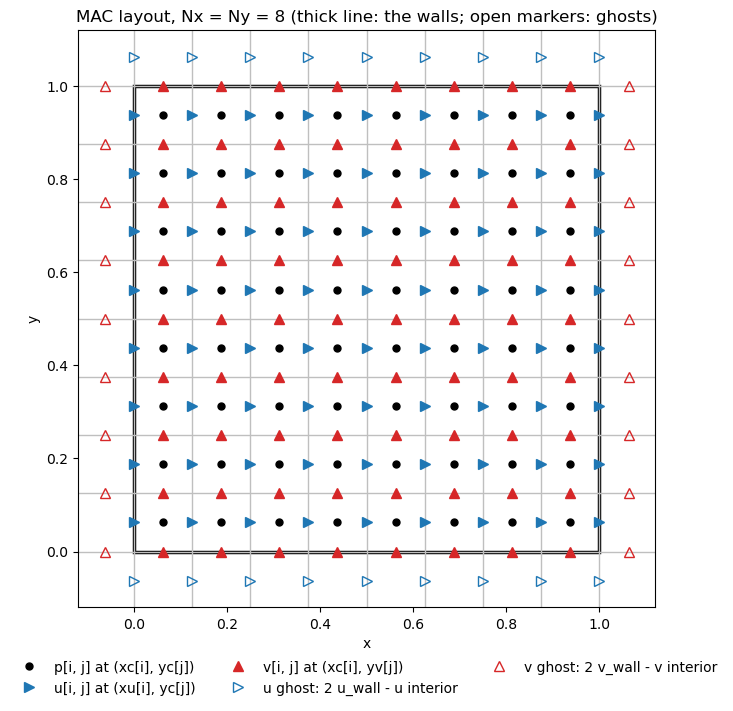

In [3]:
g = Grid(Lx=1.0, Ly=1.0, Nx=8, Ny=8, periodic_x=False, periodic_y=False)   # walls on all four sides: any Nx, Ny >= 4
print("shapes:  p", g.shape_p(), "  u", g.shape_u(), "  v", g.shape_v())
print("xu =", g.xu, "\nyu = yc =", g.yc)
print("xv = xc =", g.xc, "\nyv =", g.yv)

Xc, Yc = g.meshgrid("centres"); Xu, Yu = g.meshgrid("u"); Xv, Yv = g.meshgrid("v")
fig, ax = plt.subplots(figsize=(7.5, 7.5))
for x in g.xu:
    ax.axvline(x, color="0.75", lw=1)
for y in g.yv:
    ax.axhline(y, color="0.75", lw=1)
ax.add_patch(plt.Rectangle((0, 0), g.Lx, g.Ly, fill=False, lw=2.5, color="k"))
ax.plot(Xc.ravel(), Yc.ravel(), "o", color="k", ms=5, label="p[i, j] at (xc[i], yc[j])")
ax.plot(Xu.ravel(), Yu.ravel(), ">", color="C0", ms=7, label="u[i, j] at (xu[i], yc[j])")
ax.plot(Xv.ravel(), Yv.ravel(), "^", color="C3", ms=7, label="v[i, j] at (xc[i], yv[j])")
for yg in (-0.5 * g.dy, g.Ly + 0.5 * g.dy):                 # tangential u ghosts (eq. 35)
    ax.plot(g.xu, np.full_like(g.xu, yg), ">", mfc="none", color="C0", ms=7)
for xg in (-0.5 * g.dx, g.Lx + 0.5 * g.dx):                 # tangential v ghosts (eq. 35)
    ax.plot(np.full_like(g.yv, xg), g.yv, "^", mfc="none", color="C3", ms=7)
ax.plot([], [], ">", mfc="none", color="C0", ms=7, label="u ghost: 2 u_wall - u interior")
ax.plot([], [], "^", mfc="none", color="C3", ms=7, label="v ghost: 2 v_wall - v interior")
ax.set_aspect("equal")
ax.set_xlim(-0.12 * g.Lx, 1.12 * g.Lx); ax.set_ylim(-0.12 * g.Ly, 1.12 * g.Ly)
ax.set_xlabel("x"); ax.set_ylabel("y")
ax.set_title("MAC layout, Nx = Ny = 8 (thick line: the walls; open markers: ghosts)")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.07), ncol=3, frameon=False)
plt.show()

## 3. Ghost cells, and why boundary data enter only the right-hand side

Seibold's section 5.2 separates two kinds of boundary point. A velocity component that lives *on*
the wall ($u$ on the left and right walls, $v$ on the bottom and top) is simply set to the
prescribed value. A component that lives half a cell inside ($u$ next to the top and bottom walls,
$v$ next to the left and right walls) gets a ghost value half a cell outside, chosen so that the
average of the ghost and the first interior value is the wall value (eq. 35):

$$\frac{U_{i,j} + U_{i,j+1}}{2} = U_N \quad\Longleftrightarrow\quad U_{i,j+1} = 2U_N - U_{i,j} .$$

The pressure gets a homogeneous Neumann condition at every velocity wall, written with the same
half-cell idea (eq. 36): $P_{i,j+1} = P_{i,j}$ across the wall, i.e. the ghost pressure is a copy.

Where do the boundary values go? Section 7 of the note: the matrices for the viscous solves and
the pressure solve are built once with the *kind* of condition folded in; the *values* appear only
in the extended arrays `Ue`, `Ve` used by the explicit advection term, and in `Ubc`, `Vbc`, the
boundary contribution of the five-point stencil moved to the right-hand side of the implicit
viscosity solve. No matrix entry depends on what the wall velocity is. That is the whole reason
time-varying boundary data cost nothing: each step we re-evaluate the wall velocities at the new
time and rebuild two right-hand sides, and the factorisations stay.

pyIBM makes the boundary data callables. `BoundaryConditions(left, right, bottom, top,
bc_left=None, bc_right=None, bc_bottom=None, bc_top=None)` takes `"dirichlet"`, `"outflow"` or
`"periodic"` per side and, for a Dirichlet side, an optional function `(coordinate, t) -> (u, v)`
that is evaluated at the face coordinates along that side (`grid.yc` and `grid.yv` on the left and
right, `grid.xc` and `grid.xu` on the bottom and top). `None` means a wall at rest. `MACSolver.extend_u(u, t)`
and `extend_v(v, t)` build the ghost-padded arrays at time `t`: normal components written onto the
wall faces, tangential ghosts by eq. 35, zero-gradient copies on an outflow side, wrap-around on
periodic sides. Let us watch a moving lid go into the ghost row and into `Ubc`, and nowhere else.

In [4]:
g = Grid(1.0, 1.0, 8, 8, periodic_x=False, periodic_y=False)
def lid(x, t):                      # (u, v) on the top wall at the coordinates x and time t
    return np.sin(2 * np.pi * t) * np.ones_like(x), np.zeros_like(x)
bcs = BoundaryConditions(left=D, right=D, bottom=D, top=D, bc_top=lid)
s = MACSolver(g, rho=1.0, mu=0.01, dt=0.01, bcs=bcs)

rng = np.random.default_rng(0)
u = rng.standard_normal(g.shape_u())                  # any interior field will do
for t in (0.0, 0.25):
    ue = s.extend_u(u, t)                              # (Nx+3, Ny+2): one ghost layer each side
    u_lid = lid(g.xu, t)[0]
    gap = np.max(np.abs(0.5 * (ue[1:-1, -1] + ue[1:-1, -2]) - u_lid))
    print(f"t = {t:4.2f}: lid speed {u_lid[0]:+.3f};  max |(ghost + first interior)/2 - u_lid| = {gap:.1e}")
print("ghost row at t = 0.25 equals 2*u_lid - u[:, -1] on the interior faces:",
      np.allclose(ue[2:-2, -1], 2 * lid(g.xu[1:-1], 0.25)[0] - u[1:-1, -1]))
print("left/right wall faces hold the prescribed normal velocity (0 here), whatever u held there:",
      np.allclose(ue[1, 1:-1], 0.0) and np.allclose(ue[-2, 1:-1], 0.0))

# the implicit viscosity solve: the LU factors never see t, only the right-hand side does
c = s.nu * s.dt                                        # I + c (-L_h) is the backward Euler matrix
print("Helmholtz LU reused between calls:", s._helmholtz(c) is s._helmholtz(c))
zeros = np.zeros(g.shape_u())
for t in (0.0, 0.25):
    Ubc = c * s._lap_u(s.extend_u(zeros, t))[s._iu]    # Seibold's Ubc: the stencil applied to the data alone
    print(f"t = {t:4.2f}: max |Ubc| = {np.max(np.abs(Ubc)):.3e}, nonzero in {np.count_nonzero(Ubc)} of {Ubc.size} entries"
          f" (the row next to the lid)")

t = 0.00: lid speed +0.000;  max |(ghost + first interior)/2 - u_lid| = 0.0e+00
t = 0.25: lid speed +1.000;  max |(ghost + first interior)/2 - u_lid| = 0.0e+00
ghost row at t = 0.25 equals 2*u_lid - u[:, -1] on the interior faces: True
left/right wall faces hold the prescribed normal velocity (0 here), whatever u held there: True
Helmholtz LU reused between calls: True
t = 0.00: max |Ubc| = 0.000e+00, nonzero in 0 of 56 entries (the row next to the lid)
t = 0.25: max |Ubc| = 1.280e-02, nonzero in 7 of 56 entries (the row next to the lid)


The outflow side is our addition (Seibold's introduction lists inflow/outflow among the extensions
his students made). On an outflow side the velocity ghosts are zero-gradient copies, the pressure
is set to zero *on* the boundary (a Dirichlet value half a cell outside the last centre, so the
ghost pressure is $-P$ of the interior cell), and the normal velocity on the outflow faces is
corrected by the projection like any interior face. With one open side the Poisson matrix is no
longer singular. A closed box, on the other hand, needs the prescribed normal velocities to carry
zero net flux, otherwise the Neumann Poisson problem has no solution; `MACSolver` checks this every
step and raises `ValueError("net inflow ...")` rather than silently dropping the mismatch.

## 4. The Poisson solvers (`pyibm.fluid.poisson`)

### 4.1 One-dimensional blocks and `kron` (eq. 37)

Seibold's section 7.3 assembles the 2-D Laplace matrix from 1-D tridiagonal matrices. His
`K1(n, h, a11)` is $1/h^2$ times the $(-1, 2, -1)$ tridiagonal with the two end diagonals replaced
by $a_{11}$, and his table on p. 13 says which end condition each value encodes:

| $a_{11}$ | end condition |
|---|---|
| 1 | Neumann |
| 2 | Dirichlet, the boundary point *is* a grid point (known, dropped from the unknowns) |
| 3 | Dirichlet, the boundary lies halfway between two grid points (ghost $= -$ interior) |

All three come from inserting the boundary relation into the three-point stencil. The 2-D matrix
is `kron(speye(ny), K1x) + kron(K1y, speye(nx))` in MATLAB's column-major ravel; NumPy ravels
row-major, so pyIBM swaps the factors, `kron(Kx, I_ny) + kron(I_nx, Ky)` acting on `phi.ravel()`.

`k1(n, h, lo, hi)` is Seibold's `K1` with the two ends named instead of numbered (`"neumann"`,
`"dirichlet_point"`, `"dirichlet_mid"`, plus a circulant `"periodic"`), and
`laplacian_matrix(nx, ny, dx, dy, xlo, xhi, ylo, yhi)` is the `kron` sum. The velocity Helmholtz
matrices of section 1 are built from the same pieces: a $u$ unknown next to a left or right wall has
the wall *on* a face (`dirichlet_point`, $a_{11} = 2$), next to a bottom or top wall it has the wall
half a cell away (`dirichlet_mid`, $a_{11} = 3$), exactly as in Seibold's `Lu` and `Lv` listing.

k1(5, h = 1, lo, hi): diagonal entries for the end conditions of Seibold's table
  neumann          neumann           diag = [1. 2. 2. 2. 1.]
  dirichlet_point  dirichlet_point   diag = [2. 2. 2. 2. 2.]
  dirichlet_mid    dirichlet_mid     diag = [3. 2. 2. 2. 3.]
  neumann          dirichlet_mid     diag = [1. 2. 2. 2. 3.]
  periodic (circulant):
[[ 2. -1.  0.  0. -1.]
 [-1.  2. -1.  0.  0.]
 [ 0. -1.  2. -1.  0.]
 [ 0.  0. -1.  2. -1.]
 [-1.  0.  0. -1.  2.]]
laplacian_matrix(4, 3, ...): (12, 12) nonzeros 46  symmetric: True


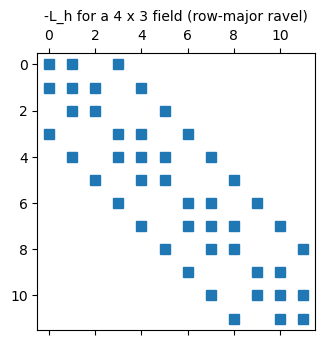

In [5]:
h = 1.0
print("k1(5, h = 1, lo, hi): diagonal entries for the end conditions of Seibold's table")
for lo, hi in (("neumann", "neumann"), ("dirichlet_point", "dirichlet_point"),
               ("dirichlet_mid", "dirichlet_mid"), ("neumann", "dirichlet_mid")):
    K = k1(5, h, lo, hi).toarray()
    print(f"  {lo:16s} {hi:16s}  diag = {np.diag(K)}")
print("  periodic (circulant):\n" + str(k1(5, h, "periodic", "periodic").toarray()))

A = laplacian_matrix(4, 3, 0.25, 0.25, "neumann", "dirichlet_mid", "neumann", "neumann")
print("laplacian_matrix(4, 3, ...):", A.shape, "nonzeros", A.nnz, " symmetric:", abs(A - A.T).max() == 0.0)
fig, ax = plt.subplots(figsize=(3.6, 3.6))
ax.spy(A, markersize=7)
ax.set_title("-L_h for a 4 x 3 field (row-major ravel)", fontsize=10)
plt.show()

### 4.2 The singular Neumann problem and its regularisation

With Neumann conditions on all four sides $-\Delta_h$ has the constant vector in its null space and
corank 1 (Seibold sec. 7.3). Because the matrix is symmetric, its range is the vectors whose sum is
zero, and the right-hand side of eq. 19 is in that range by construction: its sum is the net flux of
$U^{**}$ through the walls, which the prescribed normal velocities make zero. To use a Cholesky
factorisation Seibold adds 1 to one diagonal entry and proves (eq. 38 and the lines below it) that
the modified matrix is regular and that its solution still solves the original system for every
admissible right-hand side.

`PoissonSolver(grid, sides, regularisation=...)` offers that as `"pin"` (we add $2/dx^2 + 2/dy^2$,
the size of a typical diagonal entry, rather than 1, so the pinned matrix is as well conditioned as
a Dirichlet one) and, by default, `"bordered"`: the system $\begin{pmatrix} A & e \\ e^T & 0 \end{pmatrix}$,
the Lagrange-multiplier form of "solve $A\phi = b$ subject to mean$(\phi) = 0$". Both return the
zero-mean solution, and both drop the mean of the right-hand side, the part no solution can match
(round-off, or a user who prescribes an inflow without an outflow).

In [6]:
g = Grid(1.0, 1.0, 16, 16, periodic_x=False, periodic_y=False)
NEU = dict(left="neumann", right="neumann", bottom="neumann", top="neumann")
ps = PoissonSolver(g, NEU)                            # bordered by default
A = ps.matrix                                         # the operator -L_h itself
print("max |A @ ones| =", np.max(np.abs(A @ np.ones(A.shape[0]))), "  (the constants are in the null space)")

rhs = rng.standard_normal(g.shape_p())
print("sum of a random rhs:", f"{rhs.sum():+.4f}", " (not admissible: the solvers drop its mean)")
phi_b = ps.solve(rhs)
phi_p = PoissonSolver(g, NEU, regularisation="pin").solve(rhs)
phi_d = DCTPoissonSolver(g).solve(rhs)
print("bordered vs pin:", f"{np.max(np.abs(phi_b - phi_p)):.1e}", "   bordered vs DCT:", f"{np.max(np.abs(phi_b - phi_d)):.1e}")
res = (A @ phi_b.ravel()).reshape(g.shape_p()) - (rhs - rhs.mean())
print("residual of  -L_h phi = rhs - mean(rhs):", f"{np.max(np.abs(res)):.1e}", "   mean(phi) =", f"{phi_b.mean():.1e}")
print("make_poisson_solver picks", type(make_poisson_solver(g, NEU)).__name__, "for the all-Neumann box and",
      type(make_poisson_solver(g, {**NEU, "right": "dirichlet"})).__name__, "when a side is Dirichlet (outflow)")

max |A @ ones| = 0.0   (the constants are in the null space)
sum of a random rhs: -19.4669  (not admissible: the solvers drop its mean)
bordered vs pin: 2.9e-16    bordered vs DCT: 1.6e-17
residual of  -L_h phi = rhs - mean(rhs): 5.8e-15    mean(phi) = 0.0e+00
make_poisson_solver picks DCTPoissonSolver for the all-Neumann box and PoissonSolver when a side is Dirichlet (outflow)


### 4.3 The DCT fast path and a manufactured solution

The 1-D Neumann matrix `k1(n, h, "neumann", "neumann")` has eigenvectors $\cos\big(\pi k (j + \tfrac12)/n\big)$
with eigenvalues $(4/h^2)\sin^2(\pi k/2n)$, which is exactly the basis of the type-2 discrete cosine
transform. So on the all-Neumann box the solve is `idctn(dctn(rhs) / lambda)` with the $(0,0)$ mode
set to zero: that is `DCTPoissonSolver`, direct and $O(N\log N)$, the Dirichlet-wall analogue of the
FFT solve of the periodic back end. `make_poisson_solver(grid, sides)` picks it when every side is
Neumann (closed boxes such as the cavity) and the sparse LU otherwise (any outflow or periodic side).

A manufactured solution checks both: pick $\phi$, compute $-\Delta\phi$ by hand, solve, compare.
For the all-Neumann box we take $\phi = \cos(\pi x/L_x)\cos(2\pi y/L_y)$ (zero normal derivative on
every side and zero mean), for the Neumann/Dirichlet mix of a channel with an outflow on the right
$\phi = \cos(\pi x/2L_x)\cos(\pi y/L_y)$ (zero on the right wall). The five-point stencil should
give second-order convergence.

In [7]:
def manufactured(N, sides):
    g = Grid(1.0, 0.5, N, N // 2, periodic_x=False, periodic_y=False)      # dx = dy = 1/N
    Xc, Yc = g.meshgrid("centres")
    if sides["right"] == "neumann":
        phi = np.cos(np.pi * Xc / g.Lx) * np.cos(2 * np.pi * Yc / g.Ly)
        lam = (np.pi / g.Lx) ** 2 + (2 * np.pi / g.Ly) ** 2
    else:
        phi = np.cos(0.5 * np.pi * Xc / g.Lx) * np.cos(np.pi * Yc / g.Ly)
        lam = (0.5 * np.pi / g.Lx) ** 2 + (np.pi / g.Ly) ** 2
    t0 = time.perf_counter(); solver = make_poisson_solver(g, sides); t_setup = time.perf_counter() - t0
    t0 = time.perf_counter(); num = solver.solve(lam * phi); t_solve = time.perf_counter() - t0
    if solver.singular:
        phi = phi - phi.mean()
    return np.max(np.abs(num - phi)), type(solver).__name__, t_setup, t_solve

for sides, label in ((NEU, "all Neumann (closed box)"), ({**NEU, "right": "dirichlet"}, "Dirichlet on the right (outflow)")):
    print(label)
    prev = None
    for N in (16, 32, 64, 128):
        err, name, t_setup, t_solve = manufactured(N, sides)
        ratio = "" if prev is None else f"   ratio {prev / err:.2f}"
        print(f"  N = {N:3d}  {name:16s} max error {err:.2e}{ratio}   setup {1e3 * t_setup:6.1f} ms, solve {1e3 * t_solve:5.1f} ms")
        prev = err

all Neumann (closed box)
  N =  16  DCTPoissonSolver max error 4.59e-02   setup    0.0 ms, solve   0.3 ms
  N =  32  DCTPoissonSolver max error 1.20e-02   ratio 3.83   setup    0.0 ms, solve   0.1 ms
  N =  64  DCTPoissonSolver max error 3.03e-03   ratio 3.96   setup    0.0 ms, solve   0.1 ms
  N = 128  DCTPoissonSolver max error 7.58e-04   ratio 3.99   setup    0.0 ms, solve   0.1 ms
Dirichlet on the right (outflow)
  N =  16  PoissonSolver    max error 1.20e-02   setup    1.1 ms, solve   0.0 ms
  N =  32  PoissonSolver    max error 3.03e-03   ratio 3.96   setup    1.5 ms, solve   0.0 ms
  N =  64  PoissonSolver    max error 7.58e-04   ratio 3.99   setup    3.5 ms, solve   0.1 ms
  N = 128  PoissonSolver    max error 1.90e-04   ratio 4.00   setup   15.6 ms, solve   0.6 ms


Both solvers are second order (ratio 4 per halving of $h$). The sparse LU pays its factorisation
once, when the solver is built, and the DCT needs no setup at all; on the all-Neumann box they
agree to round-off (section 4.2) and the DCT is the one the cavity below uses.

## 5. Live cases with `MACSolver`

### 5.1 Lid-driven cavity at Re = 100 against Ghia, Ghia & Shin (1982)

Seibold's default problem: a unit box, the top wall sliding at speed 1, Re = 100, which with
$\rho = 1$ and $L = U = 1$ means $\mu = 0.01$. The reference is Ghia, Ghia & Shin, J. Comput. Phys.
48 (1982) 387-411, Table I: $u$ along the vertical line through the geometric centre of the cavity on
their $129 \times 129$ grid (we type the Re = 100 column at seventeen of their grid points). Their
solution is steady. We run the one-step scheme (`step`) to $t = 8$ on $32^2$ and $48^2$ with
$\Delta t = 0.5/N$, read $u$ on the centreline (a stored face column, $x = 0.5$) and interpolate it
to Ghia's $y$ values. A converged run would use $128^2$ and go to $t = 20$ or so; the test suite
(`tests/test_mac.py`) runs $64^2$ to $t = 10$ as a regression test.

N = 32:  512 steps in  0.2 s;  max |u - Ghia| on the centreline = 0.0153 (lid speed 1);  gamma = 0.54;  cfl = 0.69;  max |div u| = 5.3e-15;  Poisson: DCTPoissonSolver


N = 48:  768 steps in  0.5 s;  max |u - Ghia| on the centreline = 0.0108 (lid speed 1);  gamma = 0.56;  cfl = 0.72;  max |div u| = 1.1e-14;  Poisson: DCTPoissonSolver


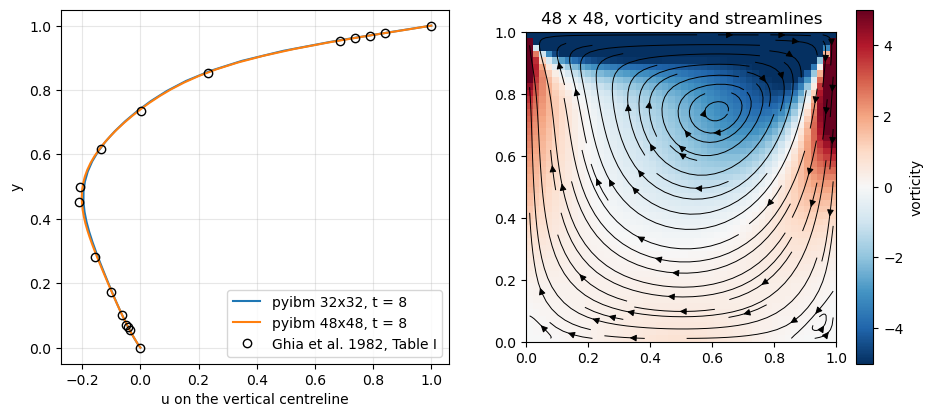

In [8]:
# Ghia, Ghia & Shin 1982, Table I, Re = 100: u on the vertical centreline at these y
GHIA_Y = np.array([1.0000, 0.9766, 0.9688, 0.9609, 0.9531, 0.8516, 0.7344, 0.6172, 0.5000,
                   0.4531, 0.2813, 0.1719, 0.1016, 0.0703, 0.0625, 0.0547, 0.0000])
GHIA_U = np.array([1.00000, 0.84123, 0.78871, 0.73722, 0.68717, 0.23151, 0.00332, -0.13641, -0.20581,
                   -0.21090, -0.15662, -0.10150, -0.06434, -0.04775, -0.04192, -0.03717, 0.00000])

def cavity(N, T, Re=100.0):
    g = Grid(1.0, 1.0, N, N, periodic_x=False, periodic_y=False)
    bcs = BoundaryConditions(D, D, D, D, bc_top=lambda x, t: (np.ones_like(x), np.zeros_like(x)))
    s = MACSolver(g, rho=1.0, mu=1.0 / Re, dt=0.5 / N, bcs=bcs)        # advection="blend", viscous="implicit"
    n = int(round(T / s.dt))
    t0 = time.perf_counter()
    for k in range(n):
        s.step(None, None, k * s.dt)                                   # no body force
    return s, n, time.perf_counter() - t0

cav = {}
for N in (32, 48):
    s, n, el = cavity(N, 8.0)
    g = s.grid
    yy = np.concatenate([[0.0], g.yc, [1.0]])                          # wall, centres, lid
    ucl = np.interp(GHIA_Y, yy, np.concatenate([[0.0], s.u[N // 2], [1.0]]))
    cav[N] = (s, ucl)
    print(f"N = {N:2d}: {n:4d} steps in {el:4.1f} s;  max |u - Ghia| on the centreline = {np.max(np.abs(ucl - GHIA_U)):.4f}"
          f" (lid speed 1);  gamma = {s._gamma(s.u, s.v, s.dt):.2f};  cfl = {s.cfl():.2f};"
          f"  max |div u| = {np.max(np.abs(s.divergence())):.1e};  Poisson: {type(s.poisson).__name__}")

s, _ = cav[48]; g = s.grid
uc = 0.5 * (s.u[:-1] + s.u[1:]); vc = 0.5 * (s.v[:, :-1] + s.v[:, 1:])   # face -> centre averages
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4.6))
for N, (sN, ucl) in cav.items():
    a1.plot(np.concatenate([[0.0], sN.u[N // 2], [1.0]]), np.concatenate([[0.0], sN.grid.yc, [1.0]]), "-", label=f"pyibm {N}x{N}, t = 8")
a1.plot(GHIA_U, GHIA_Y, "ko", mfc="none", label="Ghia et al. 1982, Table I")
a1.set_xlabel("u on the vertical centreline"); a1.set_ylabel("y"); a1.legend(); a1.grid(alpha=0.3)
om = s.vorticity()
m = a2.pcolormesh(g.xc, g.yc, om.T, cmap="RdBu_r", vmin=-5, vmax=5, shading="nearest")
a2.streamplot(g.xc, g.yc, uc.T, vc.T, color="k", density=1.0, linewidth=0.7)
fig.colorbar(m, ax=a2, label="vorticity"); a2.set_aspect("equal"); a2.set_title("48 x 48, vorticity and streamlines")
plt.show()

### 5.2 An oscillating lid, through the driver

Same box, lid velocity $U(t) = \sin 2\pi t$. This time we go through `pyibm.driver.Simulation`, the
time loop that input-file runs use, to show how boundary functions reach the solver: a case's
`hooks.py` may define `bc_top(x, t)` and friends (`docs/user-guide.md`, hooks) and the driver wires them into
`BoundaryConditions`. Here we build the `Parameters` in code and pass a `Hooks` object directly; a
fluid-only case needs no structure. We also use the `on_output` hook to collect the centreline
profile every five steps, and the driver's history for the kinetic energy.

200 midpoint steps in 0.17 s; 41 history rows; max KE 1.068e-02 J; max cfl 0.34; files written: []


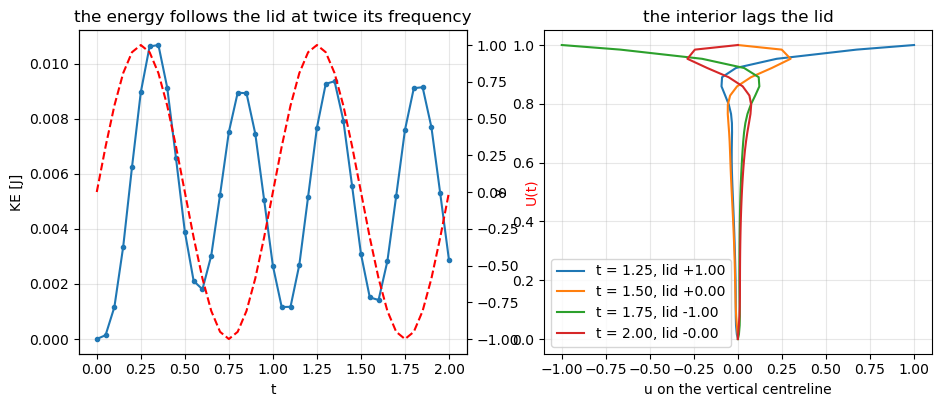

In [9]:
from pyibm.inputfile import (Parameters, FluidParams, TimeParams, GridParams, SolverParams,
                             BCParams, StructureParams, OutputParams)
from pyibm.structures import Hooks, Structure, Targets
from pyibm.driver import Simulation

N = 32
params = Parameters(fluid=FluidParams(rho=1.0, mu=0.01),
                    time=TimeParams(Tfinal=2.0, dt=0.01),
                    grid=GridParams(Nx=N, Ny=N, Lx=1.0, Ly=1.0),
                    solver=SolverParams(backend="mac", time_scheme="midpoint"),
                    bc=BCParams(left=D, right=D, bottom=D, top=D),
                    output=OutputParams(print_dump=5, save_vtk=False, save_history=False))

def bc_top(x, t):                       # the hook signature: (coordinate along the side, t) -> (u, v)
    return np.sin(2 * np.pi * t) * np.ones_like(x), np.zeros_like(x)

profiles = []
def on_output(step, t, state):          # state is the Simulation; grab u on the centreline
    profiles.append((t, state.solver.u[N // 2].copy()))

scratch = tempfile.mkdtemp()            # nothing is written (save_* are off); the driver still wants a case dir
sim = Simulation(params, case_dir=scratch, hooks=Hooks(bc_top=bc_top, on_output=on_output), output_dir=scratch, quiet=True)
res = sim.run()
h = res.history
print(f"{res.steps} midpoint steps in {res.wall_time:.2f} s; {len(h)} history rows; max KE {h.kinetic_energy.max():.3e} J;"
      f" max cfl {h.cfl.max():.2f}; files written: {os.listdir(scratch)}")

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4.2))
a1.plot(h.t, h.kinetic_energy, "-o", ms=3, label="kinetic energy")
a1.set_xlabel("t"); a1.set_ylabel("KE [J]"); a1.grid(alpha=0.3)
a1b = a1.twinx(); a1b.plot(h.t, np.sin(2 * np.pi * h.t), "r--", label="lid speed"); a1b.set_ylabel("U(t)", color="r")
a1.set_title("the energy follows the lid at twice its frequency")
yy = np.concatenate([[0.0], res.grid.yc, [1.0]])
for t, u in profiles:
    if t > 1.0 and abs(t * 4 - round(t * 4)) < 1e-9:                    # quarter periods of the second period
        a2.plot(np.concatenate([[0.0], u, [bc_top(0.0, t)[0]]]), yy, label=f"t = {t:.2f}, lid {bc_top(0.0, t)[0]:+.2f}")
a2.set_xlabel("u on the vertical centreline"); a2.set_ylabel("y"); a2.legend(); a2.grid(alpha=0.3)
a2.set_title("the interior lags the lid")
plt.show()
shutil.rmtree(scratch, ignore_errors=True)

Nothing was refactored when the lid changed direction: the LU factors built on the first step
served all 200 steps, and only the two right-hand sides changed.

### 5.3 Stokes' second problem

A flat wall oscillates in its own plane, $u(0,t) = U\cos\omega t$, under a fluid at rest far away.
The exact solution of $u_t = \nu u_{yy}$ is a damped travelling wave,

$$u(y,t) = U\,e^{-ky}\cos(\omega t - ky), \qquad k = \sqrt{\omega/2\nu},$$

with penetration depth $\delta = 1/k$. Our box has a second wall at rest at $y = L_y$, so we
compare against the finite-gap version of the same solution (oscillating Couette flow),

$$u(y,t) = U\,\mathrm{Re}\!\left[e^{i\omega t}\,\frac{\sinh\kappa(L_y - y)}{\sinh\kappa L_y}\right],
  \qquad \kappa = (1 + i)\,k,$$

which satisfies both wall conditions and reduces to the first formula as $L_y \to \infty$; the two
differ by about $e^{-kL_y}$, which we print. The box is periodic in $x$ with nothing varying in $x$,
so eight cells across are plenty; the bottom wall is a Dirichlet side with a time-varying callable,
the top wall is at rest. We start from the exact profile at $t = 0$ (no start-up transient), run two
periods, and look at the error for three resolutions with the midpoint scheme and for two time steps
with the one-step scheme.

penetration depth delta = 0.564, Ly/delta = 5.3, exp(-k Ly) = 4.9e-03


midpoint  Ny =  48 (delta/dy =  9.0), dt = 0.0050: max |u - exact| = 1.06e-03   (vs the semi-infinite formula: 2.89e-03);  max |v| = 1.3e-16


midpoint  Ny =  96 (delta/dy = 18.1), dt = 0.0050: max |u - exact| = 2.78e-04  ratio to the line above 3.81   (vs the semi-infinite formula: 2.89e-03);  max |v| = 1.9e-16


midpoint  Ny = 192 (delta/dy = 36.1), dt = 0.0050: max |u - exact| = 8.39e-05  ratio to the line above 3.31   (vs the semi-infinite formula: 2.90e-03);  max |v| = 2.2e-16


midpoint  Ny = 192 (delta/dy = 36.1), dt = 0.0025: max |u - exact| = 6.94e-05  ratio to the line above 1.21   (vs the semi-infinite formula: 2.90e-03);  max |v| = 2.5e-16
halving dy and dt together, Ny 96 -> 192: error ratio 4.00
one-step  Ny =  96, dt = 0.0050: max |u - exact| = 2.62e-03


one-step  Ny =  96, dt = 0.0025: max |u - exact| = 1.31e-03


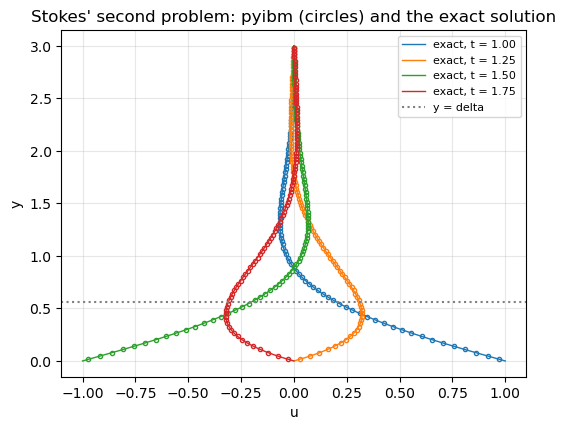

In [10]:
nu, omega, U = 1.0, 2 * np.pi, 1.0
k = np.sqrt(omega / (2 * nu)); delta = 1.0 / k
Ly = 3.0
kappa = (1 + 1j) * k
def u_semi(y, t):    return U * np.exp(-k * y) * np.cos(omega * t - k * y)
def u_exact(y, t):   return U * np.real(np.exp(1j * omega * t) * np.sinh(kappa * (Ly - y)) / np.sinh(kappa * Ly))
print(f"penetration depth delta = {delta:.3f}, Ly/delta = {Ly / delta:.1f}, exp(-k Ly) = {np.exp(-k * Ly):.1e}")

def stokes(Ny, dt, periods=2, scheme="midpoint", snap_at=()):
    Nx = 8; Lx = Nx * Ly / Ny                                    # dx = dy
    g = Grid(Lx, Ly, Nx, Ny, periodic_x=True, periodic_y=False)
    bcs = BoundaryConditions(P, P, D, D, bc_bottom=lambda x, t: (U * np.cos(omega * t) * np.ones_like(x), np.zeros_like(x)))
    s = MACSolver(g, rho=1.0, mu=nu, dt=dt, bcs=bcs)
    _, Yu = g.meshgrid("u")
    s.u[:] = u_exact(Yu, 0.0)
    snaps = []
    for j in range(int(round(periods / dt))):
        t = j * dt
        if scheme == "midpoint":
            uh, vh = s.half_step(None, None, t); s.full_step(None, None, uh, vh, t)
        else:
            s.step(None, None, t)
        if any(abs(s.t - ts) < 1e-9 for ts in snap_at):
            snaps.append((s.t, s.u[0].copy()))
    return s, snaps

prev, errs = None, {}
for Ny, dt in ((48, 0.005), (96, 0.005), (192, 0.005), (192, 0.0025)):
    s, _ = stokes(Ny, dt)
    err = errs[(Ny, dt)] = np.max(np.abs(s.u[0] - u_exact(s.grid.yc, s.t)))
    err_semi = np.max(np.abs(s.u[0] - u_semi(s.grid.yc, s.t)))
    ratio = "" if prev is None else f"  ratio to the line above {prev / err:.2f}"
    print(f"midpoint  Ny = {Ny:3d} (delta/dy = {delta / s.grid.dy:4.1f}), dt = {dt:6.4f}: max |u - exact| = {err:.2e}{ratio}"
          f"   (vs the semi-infinite formula: {err_semi:.2e});  max |v| = {np.max(np.abs(s.v)):.1e}")
    prev = err
print(f"halving dy and dt together, Ny 96 -> 192: error ratio {errs[(96, 0.005)] / errs[(192, 0.0025)]:.2f}")
for dt in (0.005, 0.0025):
    s, _ = stokes(96, dt, scheme="step")
    print(f"one-step  Ny =  96, dt = {dt:6.4f}: max |u - exact| = {np.max(np.abs(s.u[0] - u_exact(s.grid.yc, s.t))):.2e}")

s, snaps = stokes(96, 0.005, snap_at=(1.0, 1.25, 1.5, 1.75))
fig, ax = plt.subplots(figsize=(6, 4.5))
yy = np.linspace(0, Ly, 300)
for (t, u), c in zip(snaps, ("C0", "C1", "C2", "C3")):
    ax.plot(u_exact(yy, t), yy, "-", color=c, lw=1, label=f"exact, t = {t:.2f}")
    ax.plot(u, s.grid.yc, "o", color=c, ms=3, mfc="none")
ax.axhline(delta, color="0.5", ls=":", label="y = delta")
ax.set_xlabel("u"); ax.set_ylabel("y"); ax.legend(fontsize=8); ax.grid(alpha=0.3)
ax.set_title("Stokes' second problem: pyibm (circles) and the exact solution")
plt.show()

Halving $dy$ divides the midpoint error by close to four (second order in space) until, on the
finest grid, the $O(\Delta t^2)$ time error starts to show; halving $\Delta t$ there brings the
ratio back towards four. The velocity stays exactly one-dimensional ($v$ at round-off), and the
one-step scheme's error halves with $\Delta t$: backward Euler is first order in time, which is why
the driver's default is the midpoint scheme. The difference between the two exact formulas is the
$e^{-kL_y}$ effect of the top wall, well above the discretisation error, which is why we compare
against the finite-gap solution.

### 5.4 A channel with pulsed inflow and an outflow side: mass balance

A parabolic inflow on the left, $u = 4U(t)\,y(L_y - y)/L_y^2$ with $U(t) = \tfrac12(1 - \cos 2\pi t/T)$
ramping from 0 to 1 and back within $T = 1$; no-slip top and bottom; outflow on the right. The
outflow faces take part in the projection, so whatever enters must leave: after each projection the
discrete divergence is zero in every cell, and summing it over the box says the flux through the
inlet faces equals the flux through the outlet faces, to round-off, at every step, however fast the
inflow changes. The Poisson matrix now has a Dirichlet side, so it is the sparse LU, not the DCT.

Poisson solver: PoissonSolver  singular: False


250 steps; max |q_in - q_out| = 4.4e-16 m^2/s (peak q_in = 0.667);  max |div u| over the run = 3.1e-14;  final cfl = 0.03


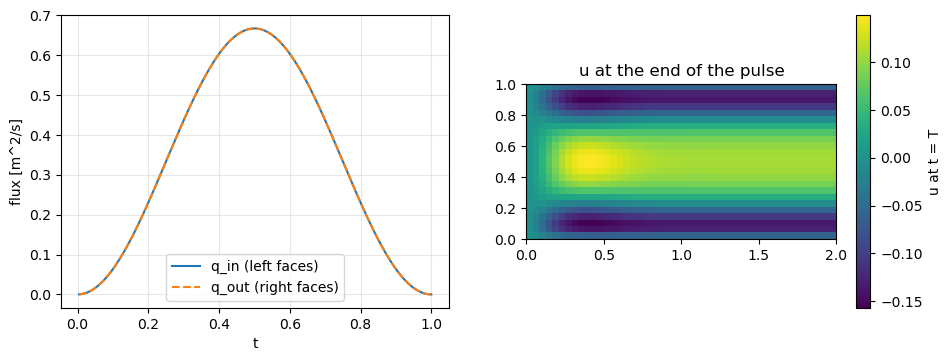

In [11]:
Lx, Ly, Nx, Ny, T = 2.0, 1.0, 48, 24, 1.0
def U_in(t):           return 0.5 * (1.0 - np.cos(2 * np.pi * t / T))
def bc_left(y, t):     return 4 * U_in(t) * y * (Ly - y) / Ly**2, np.zeros_like(y)
g = Grid(Lx, Ly, Nx, Ny, periodic_x=False, periodic_y=False)
s = MACSolver(g, rho=1.0, mu=0.02, dt=4e-3, bcs=BoundaryConditions(D, O, D, D, bc_left=bc_left))
print("Poisson solver:", type(s.poisson).__name__, " singular:", s.poisson.singular)

rows = []
for j in range(int(round(T / s.dt))):
    t = j * s.dt
    uh, vh = s.half_step(None, None, t); s.full_step(None, None, uh, vh, t)
    rows.append((s.t, s.u[0].sum() * g.dy, s.u[-1].sum() * g.dy, np.max(np.abs(s.divergence()))))
rows = np.array(rows)
print(f"{len(rows)} steps; max |q_in - q_out| = {np.max(np.abs(rows[:, 1] - rows[:, 2])):.1e} m^2/s"
      f" (peak q_in = {rows[:, 1].max():.3f});  max |div u| over the run = {rows[:, 3].max():.1e};  final cfl = {s.cfl():.2f}")

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.8))
a1.plot(rows[:, 0], rows[:, 1], "-", label="q_in (left faces)")
a1.plot(rows[:, 0], rows[:, 2], "--", label="q_out (right faces)")
a1.set_xlabel("t"); a1.set_ylabel("flux [m^2/s]"); a1.legend(); a1.grid(alpha=0.3)
uc = 0.5 * (s.u[:-1] + s.u[1:])
m = a2.pcolormesh(g.xc, g.yc, uc.T, shading="nearest", cmap="viridis")
fig.colorbar(m, ax=a2, label="u at t = T"); a2.set_aspect("equal"); a2.set_title("u at the end of the pulse")
plt.show()

## 6. One immersed body: a cylinder of target points in the channel

Now the immersed boundary. A ring of Lagrangian points, each tethered to its own initial position by
a stiff spring: a *target point* (Peskin 2002, p. 33: tie markers to target positions with stiff
springs; a body at rest is the special case of a prescribed motion). At every step the driver
interpolates the velocity to the points and moves them, computes the tether force
$f = k\,(X_{\rm target} - X)$ per unit length, spreads it to the $u$ and $v$ faces with the 4-point
delta function (Peskin & McQueen 1996 eq. 14.58, `DeltaCoupling.spread_vector` on `layout_u`,
`layout_v`), and hands the result to `half_step` and `full_step` as the body force $F_u, F_v$. The
fluid solver does not know that a body is there; it only sees a force.

We build the `Structure` in code with `pyibm.structures.Targets`, put the inflow ramp in a
`bc_left` hook, and run at $Re = UD/\nu = 10$ on a $64 \times 32$ grid, which is coarse: the
cylinder is 6.4 cells across. A resolved wake wants 20-30 cells across the body and an outflow several
diameters downstream, so a converged run of this case would be $256 \times 128$ or finer on a longer
channel. We run to $t = 8$ (3200 steps) so that the drag has time to settle. Two constraints to keep
in mind (`docs/numerics.md`): every marker must stay at least the kernel's half-width, $2h$ for
peskin4, from a non-periodic side, or part of its force would land on the wall faces, so the driver
raises an error instead; and the explicit tethers want a small enough tether number
$k\Delta t^2/\rho h$ (the driver warns above `TETHER_STABLE`, a rule of thumb from our own test
runs, 10 for target points).

40 target points, Re = U D / nu = 10, cells across the cylinder 6.4, tether number k dt^2/(rho dx) = 0.40, wall clearance 12.8 dx


3200 steps in 5.7 s;  drag on the cylinder F_x = +0.6405 N (C_D = F_x / (rho U^2 D / 2) = 6.40),  F_y = +3.7e-14;  max cfl 0.16
F_x at t = 1: 0.5161, 2: 0.5551, 4: 0.6125, 6: 0.6361, 7: 0.6392, 8: 0.6405 N
swing of F_x about its trend: 7.19 % for 0.85 <= t <= 1, 1.24 % for 1.25 <= t <= 1.5, 0.56 % for 1.5 <= t <= 2
over the last second F_x changes by +0.19 %; F_x at t = 1 is 19 % below the final value
max target error [cells] at t = 0.2: 0.036, 1: 0.150, 2: 0.466, 4: 0.906, 8: 0.991
at t = 8: largest displacement along the ring 0.989 cells, across it 0.170 cells
neighbouring markers moving in opposite directions along the ring: 65 % of the pairs; strongest Fourier mode of that displacement 16 of 40, a wavelength of 1.26 cells


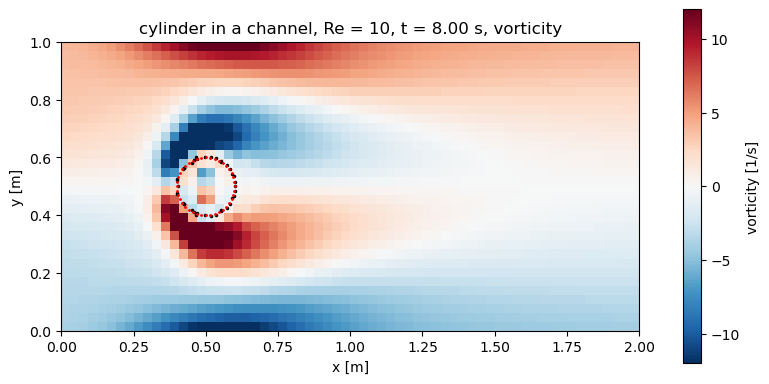

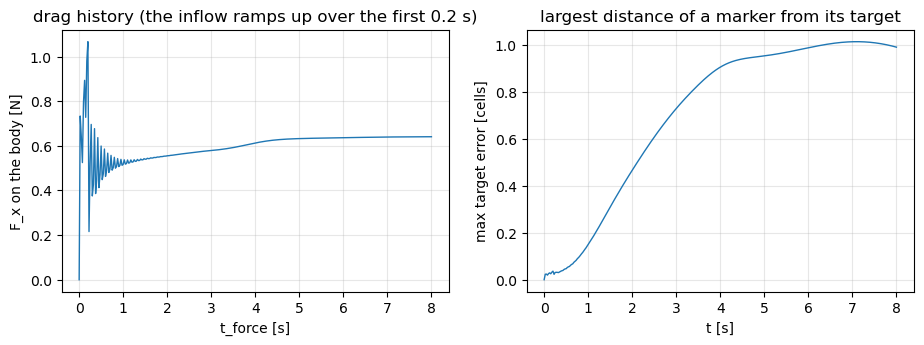

In [12]:
from pyibm.io.plot import snapshot
from IPython.display import display

Lx, Ly, Nx, Ny = 2.0, 1.0, 64, 32
g = Grid(Lx, Ly, Nx, Ny, periodic_x=False, periodic_y=False)
R, xc0, yc0 = 0.1, 0.5, 0.5
n_pts = int(round(2 * np.pi * R / (0.5 * g.dx)))               # marker spacing about dx/2
theta = 2 * np.pi * np.arange(n_pts) / n_pts
X = np.column_stack([xc0 + R * np.cos(theta), yc0 + R * np.sin(theta)])
ds = np.full(n_pts, 2 * np.pi * R / n_pts)                      # quadrature weight per point [m]
k_target = 2000.0
cyl = Structure("cylinder", X, ds, targets=Targets(idx=np.arange(n_pts), k=np.full(n_pts, k_target), X=X.copy()), X0=X.copy())

U, mu, rho, dt = 1.0, 0.02, 1.0, 2.5e-3
params = Parameters(fluid=FluidParams(rho=rho, mu=mu), time=TimeParams(Tfinal=8.0, dt=dt),
                    grid=GridParams(Nx=Nx, Ny=Ny, Lx=Lx, Ly=Ly),
                    solver=SolverParams(backend="mac", time_scheme="midpoint", coupling="delta", kernel="peskin4"),
                    bc=BCParams(left=D, right=O, bottom=D, top=D),
                    structure=StructureParams(name="cylinder", ds=float(ds[0])),
                    output=OutputParams(print_dump=10, save_vtk=False, save_history=False))
def bc_left(y, t):                                             # parabolic inflow ramped up over 0.2 s
    return 4 * U * min(1.0, t / 0.2) * y * (Ly - y) / Ly**2, np.zeros_like(y)

print(f"{n_pts} target points, Re = U D / nu = {U * 2 * R / (mu / rho):.0f}, cells across the cylinder {2 * R / g.dx:.1f},"
      f" tether number k dt^2/(rho dx) = {k_target * dt**2 / (rho * g.dx):.2f}, wall clearance {min(X[:, 1].min(), Ly - X[:, 1].max()) / g.dx:.1f} dx")
scratch = tempfile.mkdtemp()
sim = Simulation(params, case_dir=scratch, hooks=Hooks(bc_left=bc_left), structure=cyl, output_dir=scratch, quiet=True)
res = sim.run()
h = res.history
Fx = h.fx_body[-1]
print(f"{res.steps} steps in {res.wall_time:.1f} s;  drag on the cylinder F_x = {Fx:+.4f} N (C_D = F_x / (rho U^2 D / 2) = {Fx / (0.5 * rho * U**2 * 2 * R):.2f}),"
      f"  F_y = {h.fy_body[-1]:+.1e};  max cfl {h.cfl.max():.2f}")
def at(t):                                                      # the history row at time t
    return int(np.argmin(np.abs(h.t - t)))
print("F_x at t = " + ", ".join(f"{t:g}: {h.fx_body[at(t)]:.4f}" for t in (1, 2, 4, 6, 7, 8)) + " N")
def window(a, b):                                              # the force rows with a <= t_force <= b
    return (h.t_force >= a - 1e-9) & (h.t_force <= b + 1e-9)
def swing(a, b):                                               # peak to peak of F_x about its linear trend, % of its mean
    m = window(a, b)
    trend = np.polyval(np.polyfit(h.t_force[m], h.fx_body[m], 1), h.t_force[m])
    return 100 * np.ptp(h.fx_body[m] - trend) / h.fx_body[m].mean()
print("swing of F_x about its trend: " + ", ".join(f"{swing(a, b):.2f} % for {a:g} <= t <= {b:g}"
                                                    for a, b in ((0.85, 1.0), (1.25, 1.5), (1.5, 2.0))))
print(f"over the last second F_x changes by {100 * (h.fx_body[-1] / h.fx_body[window(res.t - 1.0, res.t)][0] - 1):+.2f} %; "
      f"F_x at t = 1 is {100 * (1 - h.fx_body[at(1)] / Fx):.0f} % below the final value")
print("max target error [cells] at t = " + ", ".join(f"{t:g}: {h.max_target_error_over_dx[at(t)]:.3f}" for t in (0.2, 1, 2, 4, 8)))
dX = res.structure.X - res.structure.targets.X
tangent = np.column_stack([-np.sin(theta), np.cos(theta)])
normal = np.column_stack([np.cos(theta), np.sin(theta)])
print(f"at t = {res.t:g}: largest displacement along the ring {np.abs(np.sum(dX * tangent, axis=1)).max() / g.dx:.3f} cells, "
      f"across it {np.abs(np.sum(dX * normal, axis=1)).max() / g.dx:.3f} cells")
d_tan = np.sum(dX * tangent, axis=1)                            # displacement along the ring, per marker
k_peak = 1 + int(np.argmax(np.abs(np.fft.rfft(d_tan))[1:]))    # its strongest Fourier mode around the ring
print(f"neighbouring markers moving in opposite directions along the ring: {100 * np.mean(d_tan * np.roll(d_tan, -1) < 0):.0f} % of the pairs; "
      f"strongest Fourier mode of that displacement {k_peak} of {n_pts}, a wavelength of {2 * np.pi * R / k_peak / g.dx:.2f} cells")

fig = snapshot(res.grid, res.solver.vorticity(), X=res.structure.X, targets=res.structure.targets,
               title=f"cylinder in a channel, Re = 10, t = {res.t:.2f} s, vorticity", vmax=12.0)
display(fig)
fig2, (ax, axe) = plt.subplots(1, 2, figsize=(11, 3.4))
ax.plot(h.t_force, h.fx_body, "-", lw=1); ax.set_xlabel("t_force [s]"); ax.set_ylabel("F_x on the body [N]"); ax.grid(alpha=0.3)
ax.set_title("drag history (the inflow ramps up over the first 0.2 s)")
axe.plot(h.t, h.max_target_error_over_dx, "-", lw=1); axe.set_xlabel("t [s]"); axe.set_ylabel("max target error [cells]")
axe.grid(alpha=0.3); axe.set_title("largest distance of a marker from its target")
plt.show()
shutil.rmtree(scratch, ignore_errors=True)

Two layers of opposite-sign vorticity leave the top and bottom of the cylinder and are carried
downstream, stretched along the channel, while the channel walls carry layers of the opposite sign
from the Poiseuille profile; at this Reynolds number there is no shedding. The drag rings after the
ramp ends at $t = 0.2$ (the stiff tethers and the fluid they hold form an oscillator that viscosity
damps): between $t = 0.85$ and $1$ it still swings by several percent about its trend, and the
swing is down to a fraction of a percent between $t = 1.5$ and $2$ (printed above). After that the
drag creeps up while the flow around the body settles, and over the last second of the run it
changes by only a fraction of a percent; that late value is the $C_D$ printed above. A run that
stopped at $t = 1$ would report a transient, about a fifth below it (also printed). The blockage
(the cylinder takes a fifth of the channel) and the coarse grid both push the drag above the
unconfined value, so we print $C_D$ without comparing it to a reference.

The target error grows over the run to about a cell, while the ring stays in place. That is not a
drift of the body: the displacement is mostly along the ring, not across it, and in about two thirds
of the neighbouring pairs the two markers move in opposite directions (both printed above). With
$ds = dx/2$ that pattern is about a cell long (its strongest Fourier mode is printed too). The 4-point
kernel barely sees a pattern that fine, so the fluid neither drives it strongly nor resists it, and
only the tethers hold it. `examples/cylinder_wake/README.md` describes the same wrinkle on its ring
with $ds = dx/2$, in patterns 1 to 1.7 cells long: there the target error grew to 0.64-0.70 cells
with $k = 2000$, a tether 32 times stiffer still left the ring 0.08 cells out of place, and at
$ds = dx$ the wrinkle does not grow.

## 7. The splitting error: wall slip and the pressure boundary layer

Chorin's projection as Seibold implements it, and as pyIBM's default (`projection="nonincremental"`)
implements it, is *non-incremental*: $\phi$ is the whole pressure over $\rho$, not an increment to the
previous one. The viscous substep imposes the right wall velocity on $U^{**}$ (through the ghosts of section 3).
The correction then subtracts $\Delta t\,\nabla\phi$ everywhere, including the tangential component
next to a wall, where nothing constrains it: the Neumann condition $\partial\phi/\partial n = 0$
keeps the *normal* velocity on the wall exact, and says nothing about the tangential one. The result
is a tangential wall slip

$$U_{\rm wall} = -\Delta t\,\frac{\partial\phi}{\partial\tau},$$

first order in $\Delta t$, together with a $\phi$ forced to satisfy $\partial\phi/\partial n = 0$ at
the wall whether the true pressure does or not. In Chorin's pressure $\rho\phi$ that shows up as a
numerical boundary layer of width $O(\sqrt{\nu\Delta t})$ (Brown, Cortez & Minion, J. Comput. Phys.
168, 464-499, 2001). The pressure pyIBM reports is the rotational form of section 1, the one that
matches the discrete momentum equation; the `pyibm.fluid.mac` module docstring states both
limitations and gives measured numbers, including what the rotational form changes next to an
immersed boundary.

Poiseuille flow shows the slip cleanly, because $\phi$ is linear in $x$ and the same at every height,
so the slip is one constant added to the whole profile. We run the inflow/outflow channel with a
steady parabolic inflow to steady state for several $\Delta t$ and fit the mid-channel profile to
$c_1 Q_h + c_2$, where $Q_h$ is the *discrete* parabola, the solution of $-\Delta_h Q = 1$ with
Seibold's $a_{11} = 3$ reflection at both walls (zero wall value in the sense of eq. 35), and $c_2$
is the constant the projection added. Comparing with the continuous parabola directly would mix this
$O(\Delta t)$ constant with the $O(h^2)$ difference between the discrete and the continuous
parabola, so we keep the two apart and print both. We also read the pressure gradient the solver
settled on, across the middle of the channel. The exact value is $-8\mu U/L_y^2$; the discrete one,
for the discrete parabola $c_1 Q_h$ that carries the inflow's flux without slip, is $-\mu c_1$. Then
we run the same channel with `projection="incremental"` (the next subsection explains it).

In [13]:
Lx, Ly, Nx, Ny = 2.0, 1.0, 32, 16
U, mu, rho = 1.0, 0.1, 1.0
nu = mu / rho
g = Grid(Lx, Ly, Nx, Ny, periodic_x=False, periodic_y=False)
Q_h = np.linalg.solve(k1(Ny, g.dy, "dirichlet_mid", "dirichlet_mid").toarray(), np.ones(Ny))   # -L_h Q = 1, a11 = 3
P_exact = 4 * U * g.yc * (Ly - g.yc) / Ly**2
c1_ref = P_exact.sum() / Q_h.sum()                  # c1 Q_h carries the inflow's flux with no slip
print(f"discrete vs continuous parabola: max |8U/Ly^2 Q_h - P_exact| = {np.max(np.abs(8 * U / Ly**2 * Q_h - P_exact)):.2e}  (O(h^2), independent of dt)")
print(f"pressure gradient: exact -8 mu U / Ly^2 = {-8 * mu * U / Ly**2:+.5f}, discrete -mu c1 = {-mu * c1_ref:+.5f}")

def poiseuille(dt, projection, T=4.0):
    inflow = lambda y, t: (4 * U * y * (Ly - y) / Ly**2, np.zeros_like(y))
    s = MACSolver(g, rho, mu, dt, BoundaryConditions(D, O, D, D, bc_left=inflow), projection=projection)
    _, Yu = g.meshgrid("u")
    s.u[:] = 4 * U * Yu * (Ly - Yu) / Ly**2
    for j in range(int(round(T / dt))):
        s.step(None, None, j * dt)
    u_mid = s.u[Nx // 2]
    (c1, c2), *_ = np.linalg.lstsq(np.column_stack([Q_h, np.ones(Ny)]), u_mid, rcond=None)
    fit_res = np.max(np.abs(c1 * Q_h + c2 - u_mid))
    Gx = s._gradient(s.p)[0]                      # dp/dx on the u faces
    # at mid-channel phi is linear in x, so the rotational term of p vanishes and d(p/rho)/dx = d(phi)/dx
    dphidx = Gx[Nx // 2, 0] / rho                 # at the wall-adjacent face of the middle column
    dpdx = Gx[Nx // 2].mean()                     # across the middle column
    return c2, fit_res, -dt * dphidx, dpdx

print(f"{'':7s} {'non-incremental (the default)':^52s} | {'incremental':^20s}")
print(f"{'dt':>7s} {'slip c2':>10s} {'c2/dt':>8s} {'-dt dphi/dx':>12s} {'fit residual':>13s} {'dp/dx':>8s} | {'slip c2':>10s} {'dp/dx':>9s}")
slips = []
for dt in (8e-3, 4e-3, 2e-3, 1e-3):
    c2, fit_res, pred, dpdx = poiseuille(dt, "nonincremental")
    c2_i, _, _, dpdx_i = poiseuille(dt, "incremental")
    slips.append((dt, c2, c2_i))
    print(f"{dt:7.4f} {c2:+10.3e} {c2 / dt:+8.4f} {pred:+12.3e} {fit_res:13.1e} {dpdx:+8.4f} | {c2_i:+10.1e} {dpdx_i:+9.5f}")
slips = np.array(slips)
print(f"the slip at the largest dt is {100 * slips[0, 1] / U:.2f}% of the centreline speed U = {U} (non-incremental), "
      f"{100 * abs(slips[0, 2]) / U:.4f}% (incremental)")

discrete vs continuous parabola: max |8U/Ly^2 Q_h - P_exact| = 3.91e-03  (O(h^2), independent of dt)
pressure gradient: exact -8 mu U / Ly^2 = -0.80000, discrete -mu c1 = -0.79535
                   non-incremental (the default)             |     incremental     
     dt    slip c2    c2/dt  -dt dphi/dx  fit residual    dp/dx |    slip c2     dp/dx


 0.0080 +6.297e-03  +0.7872   +6.304e-03       1.1e-05  -0.7878 |   -2.6e-06  -0.79534


 0.0040 +3.163e-03  +0.7906   +3.167e-03       7.2e-06  -0.7916 |   -2.4e-06  -0.79534


 0.0020 +1.584e-03  +0.7920   +1.587e-03       5.5e-06  -0.7934 |   -2.3e-06  -0.79534


 0.0010 +7.918e-04  +0.7918   +7.945e-04       4.6e-06  -0.7944 |   -2.3e-06  -0.79534
the slip at the largest dt is 0.63% of the centreline speed U = 1.0 (non-incremental), 0.0003% (incremental)


$c_2$ halves with $\Delta t$ and equals $-\Delta t\,\partial\phi/\partial x$ to three digits: the slip
is exactly what the correction step subtracts next to the wall, and the fit residual shows that the
computed profile really is "discrete parabola plus a constant". The pressure gradient is off by a
fixed $O(h^2)$ part (the discrete against the exact value, printed above the table) plus an
$O(\Delta t)$ part that halves with $\Delta t$ for the same reason as the slip (with the inflow flux
prescribed, a slipping profile needs less pressure gradient to carry the same flow). At the largest
$\Delta t$ the slip is below one percent of the centreline speed, harmless for most
immersed-boundary work and the reason the simple form is the default; it is not harmless if we
want the wall shear stress, and it grows with $\partial\phi/\partial\tau$, i.e. near corners and
moving bodies. The incremental columns show the fix: the slip is down at the level of the fit
residual, the same at every $\Delta t$, and the pressure gradient sits on the discrete value.

### The incremental projection and the rotational pressure update

The fix is standard (Brown, Cortez & Minion 2001; Guermond, Minev & Shen, Comput. Methods Appl.
Mech. Engrg. 195, 2006), and `MACSolver(..., projection="incremental")` implements it (input-file
key `mac_projection = "incremental"` in the `Solver` block). We keep $\phi$ a pressure over $\rho$.
The predictor carries the previous pressure, $U^* = \ldots - (\Delta t/\rho)\,\nabla p^{\,n-1/2}$,
and the Poisson solve then returns only an increment $\phi$. Now $\partial\phi/\partial\tau$ is
itself $O(\Delta t)$, so the slip drops to $O(\Delta t^2)$, and at a steady state the increment and
the slip vanish, which is what the table shows. The pressure update is the *rotational* one,

$$p^{\,n+1/2} = p^{\,n-1/2} + \rho\,\big(\phi - \theta\,\nu\,\nabla_h\cdot U^{**}\big),$$

with $U^{**}$ the post-viscous field that goes into the Poisson solve and $\theta$ the implicit
weight of the viscous step: $\theta = 1$ for `step` and `half_step` (backward Euler), $\theta = 1/2$
for `full_step` (Crank-Nicolson). Since $\nabla_h\cdot U^{**} = \tau\,L_h\phi$ for a substep of length
$\tau$ ($\Delta t$, or $\Delta t/2$ in `half_step`), the extra term is $-\rho\,\theta\nu\tau\,L_h\phi$,
the same correction that makes the reported pressure of the
non-incremental default rotational (there without $p^{\,n-1/2}$). The rotational form makes the
pressure's wall condition consistent, which shrinks the numerical boundary layer that the plain
incremental update leaves in $p$, and the velocity is second order. For the pressure, Brown, Cortez & Minion find second order in their channel analysis;
the general-domain estimate (Guermond & Shen 2004, as reviewed by Guermond, Minev & Shen 2006) is
$\Delta t^{3/2}$ in $L^2$. Two further rules for time-varying walls (both followed here): impose the
wall velocity on $U^{**}$ at $t^{n+1}$, not $t^n$, and never derive a pressure boundary condition
from the momentum equation at the wall; $\partial\phi/\partial n = 0$ is the only consistent choice
once the normal velocity of $U^{**}$ matches the wall, and the wall's acceleration enters the
pressure through $\nabla\cdot U^{**}$ on its own. The `pyibm.fluid.mac` module docstring gives the
measured convergence of both variants on a Taylor-Green vortex with moving walls.

## 8. Summary

- One MAC projection step is three substeps: explicit advection in conservative form with the
  central/upwind blend (eqs. 26-34), implicit viscosity by two pre-factored sparse solves
  (eqs. 14-15), and Chorin's projection with a Neumann Poisson problem (eqs. 16-19). `MACSolver.step`
  is Seibold's loop plus a body force; `half_step`/`full_step` is the second-order midpoint version.
- Boundary data live in ghost cells (eq. 35) and in right-hand sides (Seibold's `Ubc`, `Vbc`), never in
  a matrix, so `BoundaryConditions` can take functions of (coordinate, t) at no cost.
- The Poisson matrix is a `kron` sum of 1-D tridiagonals with Seibold's $a_{11} \in \{1, 2, 3\}$ ends
  (eq. 37); on a closed box it is singular and regularised (bordered or pinned), and it is diagonalised
  by the DCT, which is the fast path.
- The coarse-grid cavity sits close to Ghia et al. (1982) Table I, an oscillating lid and a pulsed
  channel run with time-varying data and exact mass balance, Stokes' second problem converges at
  second order in space with the midpoint scheme, and a cylinder of target points drops into the
  same solver through the driver.
- The non-incremental projection (the default) leaves an $O(\Delta t)$ tangential slip at walls and
  a pressure boundary layer; `MACSolver(projection="incremental")`, the incremental projection with
  the rotational pressure update, removes the slip. The reported pressure is the rotational form in
  both variants.

## References

- B. Seibold, A compact and fast Matlab code solving the incompressible Navier-Stokes equations on rectangular domains, course notes for MIT 18.086 (2008).
- A. J. Chorin, Numerical solution of the Navier-Stokes equations, *Math. Comp.* 22 (1968) 745-762.
- U. Ghia, K. N. Ghia and C. T. Shin, High-Re solutions for incompressible flow using the Navier-Stokes equations and a multigrid method, *J. Comput. Phys.* 48 (1982) 387-411.
- C. S. Peskin and D. M. McQueen, Fluid dynamics of the heart and its valves, chapter 14 of H. G. Othmer, F. R. Adler, M. A. Lewis and J. C. Dallon (eds.), *Case Studies in Mathematical Modeling: Ecology, Physiology, and Cell Biology* (Prentice Hall, 1996), pp. 313-342.
- C. S. Peskin, The immersed boundary method, *Acta Numerica* 11 (2002) 479-517.
- D. L. Brown, R. Cortez and M. L. Minion, Accurate projection methods for the incompressible Navier-Stokes equations, *J. Comput. Phys.* 168 (2001) 464-499.
- J. L. Guermond and J. Shen, On the error estimates for the rotational pressure-correction projection methods, *Math. Comp.* 73 (2004) 1719-1737.
- J. L. Guermond, P. Minev and J. Shen, An overview of projection methods for incompressible flows, *Comput. Methods Appl. Mech. Engrg.* 195 (2006) 6011-6045.

In [14]:
print(f"whole notebook: {time.perf_counter() - T_START:.1f} s of compute on this machine")

whole notebook: 15.4 s of compute on this machine
